SKILLCRAFT MACHINE LEARNING INTERNSHIIP TASK 3

In [2]:
%pip install opencv-python-headless

   ---------------------------------------- 0.0/43.8 MB ? eta -:--:--
   ---------------------------------------- 0.3/43.8 MB ? eta -:--:--
    --------------------------------------- 1.0/43.8 MB 3.9 MB/s eta 0:00:12
   - -------------------------------------- 1.8/43.8 MB 3.7 MB/s eta 0:00:12
   -- ------------------------------------- 2.6/43.8 MB 3.7 MB/s eta 0:00:12
   --- ------------------------------------ 3.4/43.8 MB 4.0 MB/s eta 0:00:11
   ---- ----------------------------------- 4.5/43.8 MB 3.8 MB/s eta 0:00:11
   ----- ---------------------------------- 5.5/43.8 MB 4.0 MB/s eta 0:00:10
   ----- ---------------------------------- 6.3/43.8 MB 4.1 MB/s eta 0:00:10
   ----- ---------------------------------- 6.3/43.8 MB 4.1 MB/s eta 0:00:10
   ------ --------------------------------- 7.1/43.8 MB 3.5 MB/s eta 0:00:11
   ------- -------------------------------- 7.9/43.8 MB 3.6 MB/s eta 0:00:11
   -------- ------------------------------- 8.9/43.8 MB 3.6 MB/s eta 0:00:10
   -------- -

In [3]:
import os
import random
import cv2
import numpy as np
import matplotlib.pyplot as plt
import joblib

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

print("Libraries imported successfully!")

Libraries imported successfully!


In [6]:
import os

print("Notebook working directory:", os.getcwd())
print("Files and folders:", os.listdir())

Notebook working directory: d:\myfiles\DHANLAXMI\SkillCraft-ML-Internship\SCT_ML_3
Files and folders: ['.git', 'SCT_ML_Task3_Cats_vs_Dogs.ipynb']


In [10]:
import os

dataset_dir = r"D:\myfiles\DHANLAXMI\SkillCraft-ML-Internship\SCT_ML_3"

print("Dataset path exists:", os.path.exists(dataset_dir))

if os.path.exists(dataset_dir):
    print("Folders:", os.listdir(dataset_dir))
else:
    print("Path not found. Update dataset_dir to your actual PetImages folder.")

Dataset path exists: True
Folders: ['.git', 'PetImages', 'SCT_ML_Task3_Cats_vs_Dogs.ipynb']


In [14]:
import os

dataset_dir = r"D:\myfiles\DHANLAXMI\SkillCraft-ML-Internship\SCT_ML_3"

print("Path exists:", os.path.exists(dataset_dir))

if os.path.exists(dataset_dir):
    print("Folders:", os.listdir(dataset_dir))

Path exists: True
Folders: ['.git', 'PetImages', 'SCT_ML_Task3_Cats_vs_Dogs.ipynb']


In [16]:
dataset_dir = r"D:\myfiles\DHANLAXMI\SkillCraft-ML-Internship\SCT_ML_3\PetImages"

In [17]:

import os
import cv2
import random
import numpy as np

random.seed(42)

X = []
y = []

for folder, label in [("Cat", 0), ("Dog", 1)]:
    folder_path = os.path.join(dataset_dir, folder)

    if not os.path.isdir(folder_path):
        raise FileNotFoundError(
            f"Folder not found: {folder_path}"
        )

    filenames = [
        f for f in os.listdir(folder_path)
        if f.lower().endswith(
            (".jpg", ".jpeg", ".png", ".bmp", ".webp")
        )
    ]

    random.shuffle(filenames)
    count = 0

    for filename in filenames:
        image_path = os.path.join(folder_path, filename)
        image = cv2.imread(image_path)

        if image is None:
            continue

        image = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
        image = cv2.resize(image, (32, 32))

        X.append(image.flatten())
        y.append(label)
        count += 1

        if count >= 1000:
            break

    print(f"{folder} images processed: {count}")

X = np.array(X, dtype=np.float32)
y = np.array(y, dtype=np.int64)

print("Feature matrix:", X.shape)
print("Labels:", y.shape)

if len(X) == 0:
    print("ERROR: No images loaded. Check dataset_dir.")
elif len(set(y)) < 2:
    print("ERROR: Both Cat and Dog images are required.")
else:
    print("Dataset loaded successfully!")


Cat images processed: 1000
Dog images processed: 1000
Feature matrix: (2000, 1024)
Labels: (2000,)
Dataset loaded successfully!


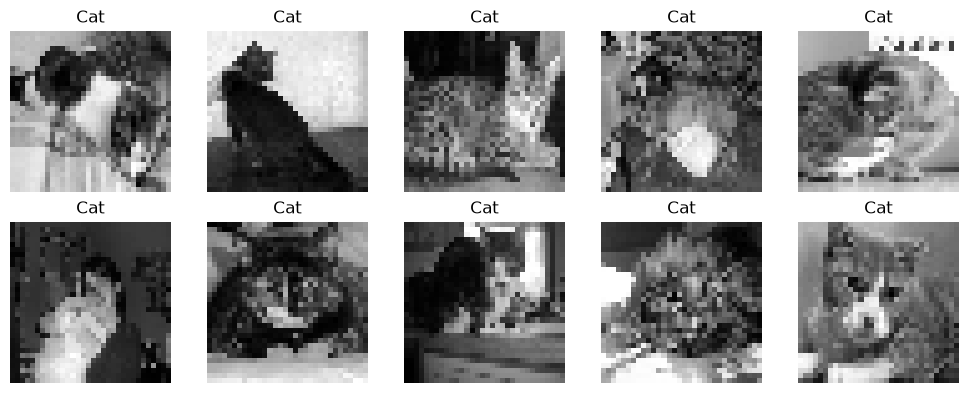

In [18]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 4))

for i in range(min(10, len(X))):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X[i].reshape(32, 32), cmap="gray")
    plt.title("Cat" if y[i] == 0 else "Dog")
    plt.axis("off")

plt.tight_layout()
plt.show()

In [19]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 1600
Testing samples: 400


In [20]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

pca = PCA(n_components=100, random_state=42)

X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca = pca.transform(X_test_scaled)

print("Training shape:", X_train_pca.shape)
print("Testing shape:", X_test_pca.shape)
print(
    "Variance retained:",
    round(pca.explained_variance_ratio_.sum() * 100, 2),
    "%"
)

Training shape: (1600, 100)
Testing shape: (400, 100)
Variance retained: 85.08 %


In [21]:
from sklearn.svm import SVC

svm_model = SVC(
    kernel="rbf",
    C=1.0,
    gamma="scale"
)

svm_model.fit(X_train_pca, y_train)

print("SVM model trained successfully!")

SVM model trained successfully!


In [22]:
from sklearn.metrics import accuracy_score

y_pred = svm_model.predict(X_test_pca)

accuracy = accuracy_score(y_test, y_pred)

print(f"Model Accuracy: {accuracy * 100:.2f}%")

Model Accuracy: 60.00%


In [23]:
from sklearn.metrics import classification_report

print(
    classification_report(
        y_test,
        y_pred,
        labels=[0, 1],
        target_names=["Cat", "Dog"],
        zero_division=0
    )
)

              precision    recall  f1-score   support

         Cat       0.60      0.61      0.61       200
         Dog       0.60      0.58      0.59       200

    accuracy                           0.60       400
   macro avg       0.60      0.60      0.60       400
weighted avg       0.60      0.60      0.60       400



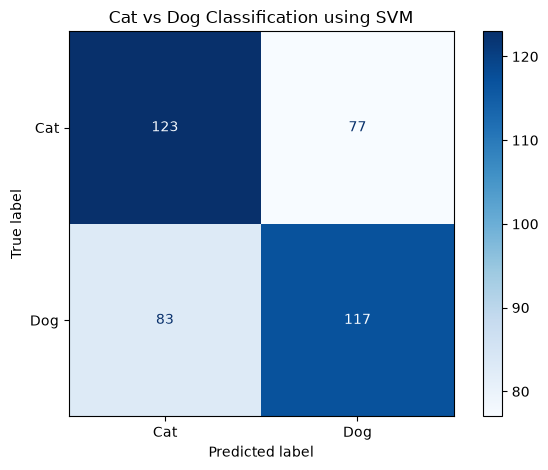

In [24]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Cat", "Dog"]
)

disp.plot(cmap="Blues")
plt.title("Cat vs Dog Classification using SVM")
plt.tight_layout()
plt.savefig("confusion_matrix.png", dpi=300)
plt.show()

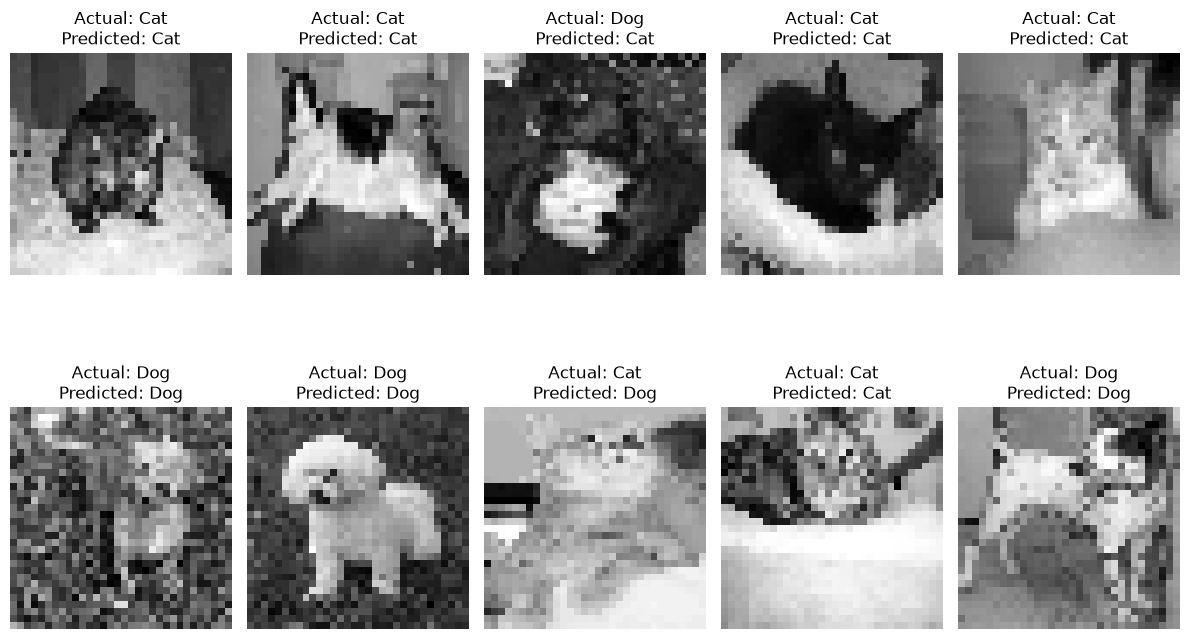

In [25]:
plt.figure(figsize=(12, 8))

for i in range(min(10, len(X_test))):
    actual = "Cat" if y_test[i] == 0 else "Dog"
    predicted = "Cat" if y_pred[i] == 0 else "Dog"

    plt.subplot(2, 5, i + 1)
    plt.imshow(X_test[i].reshape(32, 32), cmap="gray")
    plt.title(f"Actual: {actual}\nPredicted: {predicted}")
    plt.axis("off")

plt.tight_layout()
plt.savefig("sample_predictions.png", dpi=300)
plt.show()

In [26]:
import os
import joblib

os.makedirs("artifacts", exist_ok=True)

joblib.dump(svm_model, "artifacts/svm_model.pkl")
joblib.dump(scaler, "artifacts/scaler.pkl")
joblib.dump(pca, "artifacts/pca.pkl")

print("Model, scaler, and PCA saved successfully!")

Model, scaler, and PCA saved successfully!


Prediction: CAT 🐱


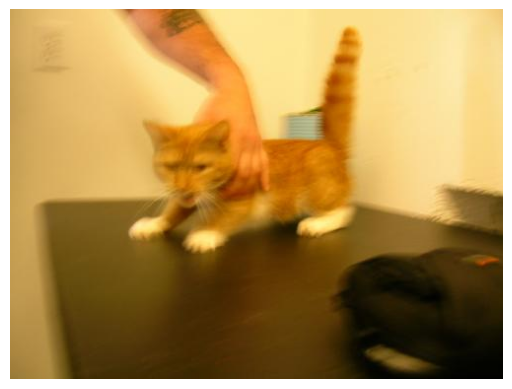

In [28]:
from tkinter import Tk, filedialog

root = Tk()
root.withdraw()
root.attributes("-topmost", True)

image_path = filedialog.askopenfilename(
    title="Select a Cat or Dog Image",
    filetypes=[("Image files", "*.jpg *.jpeg *.png *.bmp")]
)

root.destroy()

if image_path:
    import cv2
    import numpy as np
    import matplotlib.pyplot as plt

    image = cv2.imread(image_path)

    if image is None:
        print("Could not read the selected image.")
    else:
        gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
        resized = cv2.resize(gray, (32, 32))

        features = resized.flatten().astype(np.float32).reshape(1, -1)
        features_scaled = scaler.transform(features)
        features_pca = pca.transform(features_scaled)

        prediction = svm_model.predict(features_pca)[0]

        print("Prediction:", "CAT 🐱" if prediction == 0 else "DOG 🐶")

        plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
        plt.axis("off")
        plt.show()
else:
    print("No image selected.")

In [29]:
import os

os.makedirs("results", exist_ok=True)

# Save the confusion matrix and prediction plots
plt.figure(figsize=(6, 5))
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Cat", "Dog"]
)
disp.plot(cmap="Blues")
plt.title("Cat vs Dog - SVM Confusion Matrix")
plt.tight_layout()
plt.savefig("results/confusion_matrix.png", dpi=300)
plt.close()

print("Evaluation graph saved!")

Evaluation graph saved!


<Figure size 600x500 with 0 Axes>